# 01 · The volume: chunks, air and papyrus

**Goal.** Read one small 3D block of the scroll, and learn the three things every later step depends on:
the pyramid and chunk layout, what intensities mean, and how a sheet looks in three orthogonal views.

**Data.** PHerc. 139, the 9.362 µm scan, pyramid level 1 (18.7 µm voxels), one 256³ block near the middle.

In [ ]:
# On Google Colab: fetch the code and the two missing libraries. Locally this cell does nothing.
import sys, os
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/vesuvius-labs'):
        !git clone -q https://github.com/alexchilton/vesuvius-labs /content/vesuvius-labs
        !pip -q install "zarr<3" s3fs tifffile
    os.chdir('/content/vesuvius-labs/notebooks')

In [1]:
import sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
import vlab
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray'})

In [2]:
v1 = vlab.scroll_volume(1)
zc, yc, xc = v1.shape[0] // 2, 1500, 1500
t = time.time(); B = vlab.crop(v1, 'v1block', slice(zc, zc + 256), slice(yc, yc + 256), slice(xc, xc + 256))
print(f'block {B.shape} {B.dtype}, {B.nbytes / 1e6:.0f} MB, streamed in {time.time() - t:.1f}s')
print('chunks touched:', np.prod([int(np.ceil(256 / c)) + 1 for c in v1.chunks]), 'at most (128³ each)')

block (256, 256, 256) uint8, 17 MB, streamed in 4.1s
chunks touched: 27 at most (128³ each)


## 1. What the numbers mean

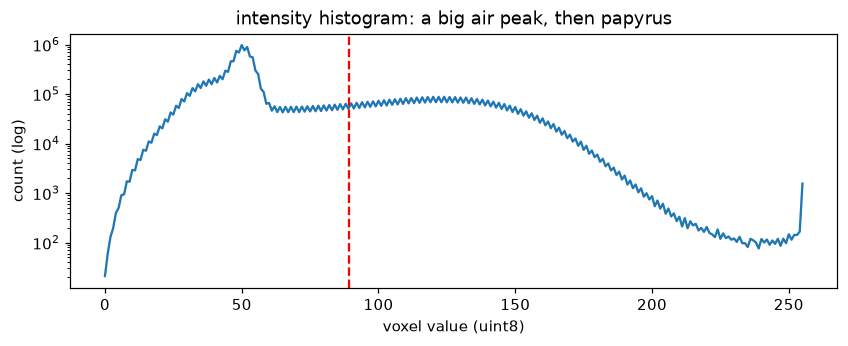

fraction above 89: 0.292


In [3]:
h = np.bincount(B.ravel(), minlength=256)
plt.figure(figsize=(9, 3)); plt.semilogy(h); plt.xlabel('voxel value (uint8)'); plt.ylabel('count (log)')
thr = 255 * 0.35
plt.axvline(thr, c='r', ls='--'); plt.title('intensity histogram: a big air peak, then papyrus'); plt.show()
print(f'fraction above {thr:.0f}: {(B > thr).mean():.3f}')

The volume is **masked** (outside the scroll is 0) and quantised to 8 bits. Air sits low; papyrus higher.
A threshold separates them roughly; it fails where sheets touch, which is exactly where the real models are needed.

## 2. Three orthogonal views

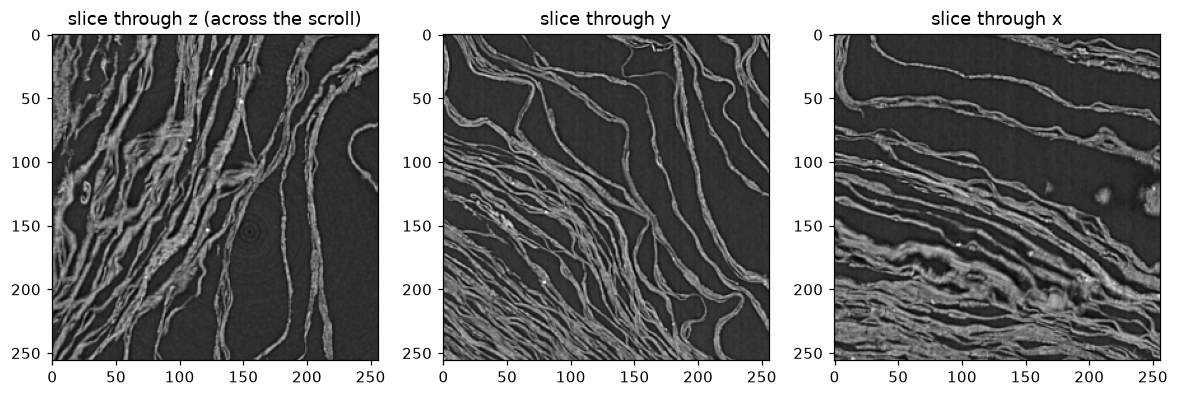

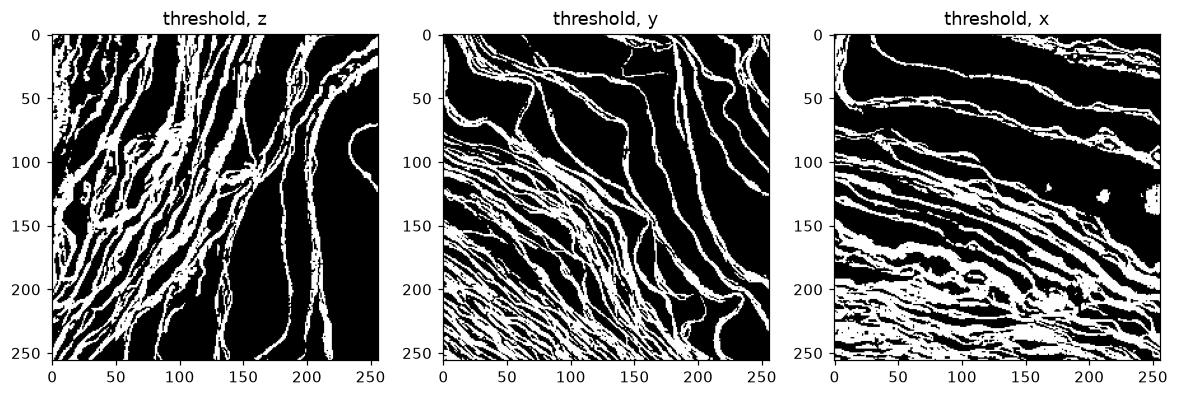

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
for a, (img, t) in zip(ax, [(B[128], 'z (across the scroll)'), (B[:, 128], 'y'), (B[:, :, 128], 'x')]):
    a.imshow(img); a.set_title(f'slice through {t}')
plt.show()
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
for a, (img, t) in zip(ax, [(B[128] > thr, 'z'), (B[:, 128] > thr, 'y'), (B[:, :, 128] > thr, 'x')]):
    a.imshow(img); a.set_title(f'threshold, {t}')
plt.show()

## 3. Sheets have a direction

Papyrus is a thin sheet, so locally the intensity changes fast *across* it and slowly *along* it.
The **structure tensor** (averaged outer product of the gradient) captures that: its largest eigenvector is the sheet
normal. This is the classical, model-free way to find sheets, and the normal is what notebook 02 samples along.

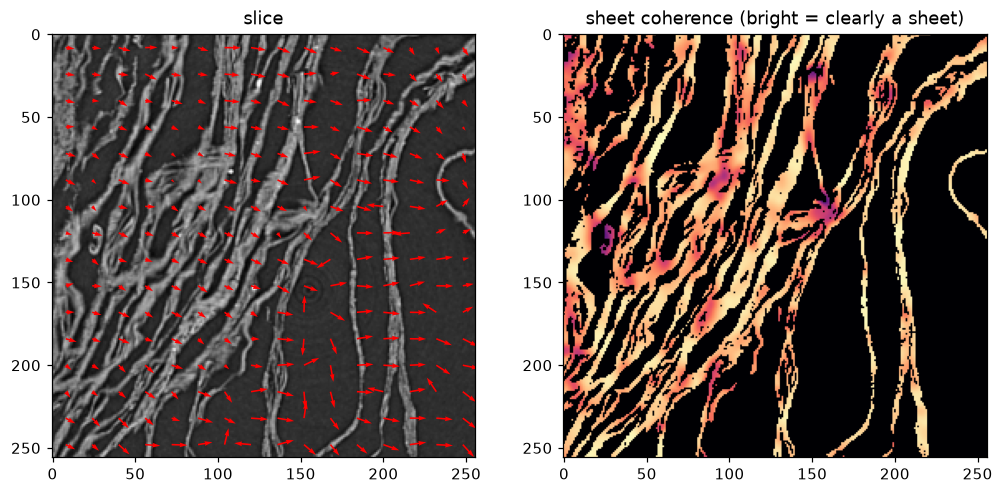

In [5]:
from scipy.ndimage import gaussian_filter, sobel
Bf = gaussian_filter(B.astype(np.float32), 1.0)
g = [sobel(Bf, axis=i) for i in range(3)]
J = np.empty(B.shape + (3, 3), np.float32)
for i in range(3):
    for j in range(3):
        J[..., i, j] = gaussian_filter(g[i] * g[j], 3.0)
w, v = np.linalg.eigh(J[128])                      # one z-slice, 256 x 256 tensors
coh = (w[..., 2] - w[..., 1]) / (w[..., 2] + w[..., 1] + 1e-6)   # 1 = clean sheet, 0 = isotropic
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(B[128]); ax[0].set_title('slice')
ax[1].imshow(coh * (B[128] > thr), cmap='magma'); ax[1].set_title('sheet coherence (bright = clearly a sheet)')
ys, xs = np.mgrid[8:256:16, 8:256:16]; n = v[ys, xs, :, 2]
ax[0].quiver(xs, ys, n[..., 2], -n[..., 1], color='r', scale=25); plt.show()

Red arrows: the estimated normal (in-plane part). They point across the wraps. Coherence drops where wraps touch
or the sheet is damaged.

## Check yourself

1. Why is a global threshold not enough to separate two touching wraps?
2. The structure tensor's normal has a sign ambiguity. Why does that matter when you sample "in front of" a sheet?
3. Which pyramid level would you use to find the scroll's outline, and which to see fibres?